# Explore > Healthy Life Expectancy at Birth _(years)_

# Imports

In [1]:
import matplotlib.pyplot as plt
from scipy import stats

from Q1_OLD_OLD.consts import *

from utils.read_csv_to_df import read_csv_to_df
from utils.plot_hist_with_normal_dist_overlay import plot_hist_with_normal_dist_overlay
from utils.rule_of_thumb__skewness import rule_of_thumb__skewness
from utils.rule_of_thumb__kurtosis import rule_of_thumb__kurtosis
from utils.plot_correlation_to_target import plot_correlation_to_target
from utils.preprocessing.transform import *

# Defaults

In [2]:
COLUMN = columns['HLEAB']

# Fetch Data

In [3]:
train_df = read_csv_to_df(path=TRAIN_PATH)

---

# Summary

In [4]:
train_df[COLUMN].info()

HealthyLifeExpectancy_stats = train_df[[COLUMN]].describe().T

q1, q3 = train_df[COLUMN].quantile(0.25), train_df[COLUMN].quantile(0.75)
iqr = q3 - q1
HealthyLifeExpectancy_stats['IQR outliers'] = (
	(train_df[COLUMN] < q1 - 1.5 * iqr) | (train_df[COLUMN] > q3 + 1.5 * iqr)
).sum()

HealthyLifeExpectancy_stats

<class 'pandas.core.series.Series'>
RangeIndex: 1559 entries, 0 to 1558
Series name: Healthy life expectancy at birth
Non-Null Count  Dtype  
--------------  -----  
1522 non-null   float64
dtypes: float64(1)
memory usage: 12.3 KB


,count,mean,std,min,25%,50%,75%,max,IQR outliers
Healthy life expectancy at birth,1522.0,63.33168,7.478307,32.3,58.34,65.18,68.535,77.1,7


In [5]:
missing_values_HealthyLifeExpectancy = train_df[COLUMN].isna().sum()
count_HealthyLifeExpectancy = train_df[COLUMN].count()

print(f"{missing_values_HealthyLifeExpectancy} missing values out of {count_HealthyLifeExpectancy} -> {round(missing_values_HealthyLifeExpectancy / count_HealthyLifeExpectancy, 2)}%")

37 missing values out of 1522 -> 0.02%


# Plots

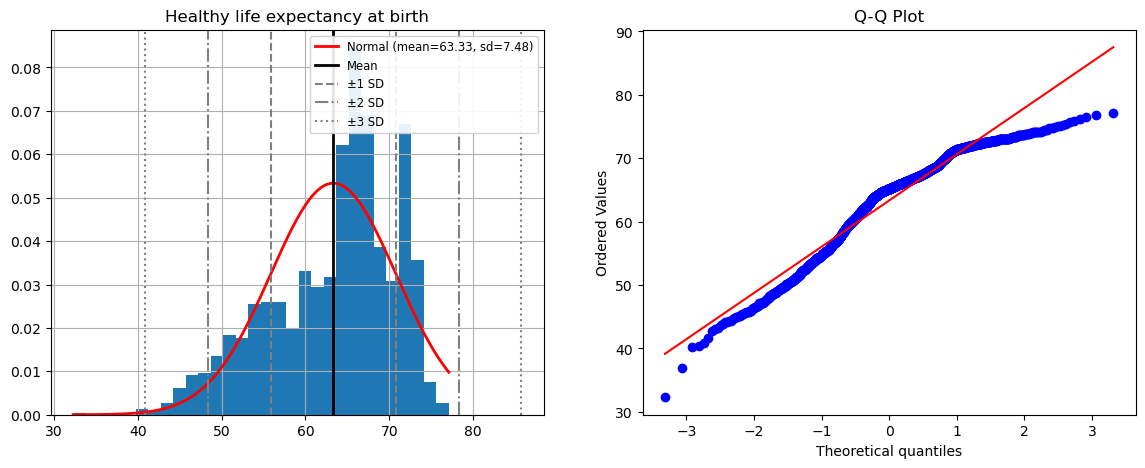

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

plot_hist_with_normal_dist_overlay(
    series=train_df[COLUMN],
    bins=HIST_BINS,
    ax=ax1
)

stats.probplot(
	train_df[COLUMN].dropna(),
	dist="norm",
	plot=ax2)
ax2.set_title("Q-Q Plot")

plt.show()

# Correlation to Target

<Axes: title={'center': 'Life Ladder vs Healthy life expectancy at birth'}, xlabel='Healthy life expectancy at birth', ylabel='Life Ladder'>

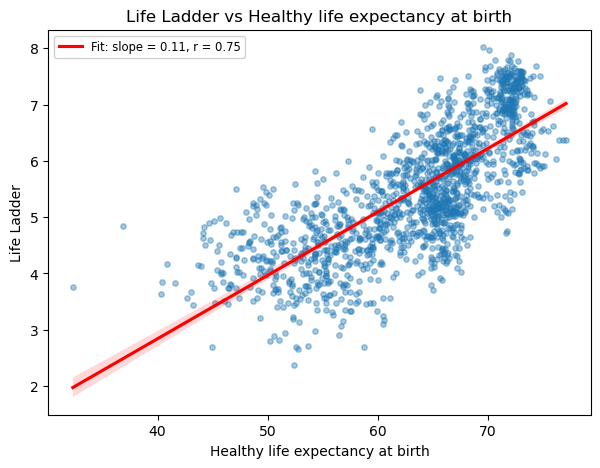

In [7]:
plot_correlation_to_target(
	df=train_df,
	feature="Healthy life expectancy at birth",
	target=TARGET,
)

In [8]:
correlation_to_target_HealthyLifeExpectancy = train_df[TARGET].corr(train_df["Healthy life expectancy at birth"])
print(f"Correlation: {correlation_to_target_HealthyLifeExpectancy:.3f}")

Correlation: 0.751


# Skew & Kurtosis

In [9]:
HealthyLifeExpectancySkew = train_df[COLUMN].skew()
HealthyLifeExpectancySkew_RuleOfThumb = rule_of_thumb__skewness(series=train_df["Healthy life expectancy at birth"])
HealthyLifeExpectancyKurtosis = train_df[COLUMN].kurt()
HealthyLifeExpectancyKurtosis_RuleOfThumb = rule_of_thumb__kurtosis(series=train_df[COLUMN])

print(f'Healthy Life Expectancy Skew: {HealthyLifeExpectancySkew:.3f} -> {HealthyLifeExpectancySkew_RuleOfThumb}')
print(f'Healthy Life Expectancy Kurtosis: {HealthyLifeExpectancyKurtosis:.3f} -> {HealthyLifeExpectancyKurtosis_RuleOfThumb}')

Healthy Life Expectancy Skew: -0.723 -> Moderately skewed
Healthy Life Expectancy Kurtosis: -0.093 -> Mesokurtic (near-normal tails)


In [10]:
HealthyLifeExpectancySkewTransformed = compare_all_transforms(series=train_df["Healthy life expectancy at birth"])
HealthyLifeExpectancySkewTransformed

,skew_before,skew_after,skew_diff,kurt_before,kurt_after,kurt_diff,skew_rule_after
transform,,,,,,,
rank,-0.722594,-0.001462,0.721132,-0.092659,-1.200586,-1.107926,Roughly symmetric
quantile,-0.722594,0.002027,0.724621,-0.092659,0.641501,0.734161,Roughly symmetric
yeo_johnson,-0.722594,-0.141241,0.581353,-0.092659,-0.826676,-0.734016,Roughly symmetric
box_cox,-0.722594,-0.142019,0.580575,-0.092659,-0.826984,-0.734325,Roughly symmetric
cube,-0.722594,-0.257191,0.465403,-0.092659,-0.765862,-0.673202,Roughly symmetric
reflect_log,-0.722594,-0.427017,0.295578,-0.092659,0.078224,0.170883,Roughly symmetric
square,-0.722594,-0.476134,0.246460,-0.092659,-0.541610,-0.448950,Roughly symmetric
clip,-0.722594,-0.664976,0.057618,-0.092659,-0.385575,-0.292916,Moderately skewed
shift,-0.722594,-0.722594,0.000000,-0.092659,-0.092659,0.000000,Moderately skewed


---

### Notes / Observations
#### General
- 37 missing values (2.4% of rows).
- Measured in years (32 to 77, mean 63.3, median 65.2), a very different scale from the 0 to 1 features.
- Left skewed (skew -0.72) with two peaks near 66 and 72 years, plus 7 low IQR outliers (below about 43 years).
- The QQ plot bunches up at the top (many countries hit a similar ceiling) and has a long low tail.
- Strong positive link to happiness (r = 0.75). The happiest countries cluster at 70+ years.
- Very closely tied to GDP (r = 0.85), so it largely repeats the same "wealth and development" information.
- **Takeaway:** strong predictor, but it overlaps heavily with GDP and needs scaling.

#### Transforming
- Moderately left skewed, so a transform helps but is not critical.
- yeo_johnson gives the best result while keeping magnitudes: skew -0.72 to -0.14.
- cube (-0.26) and square (-0.48) also work and are easier to explain, but in years they create huge numbers (77 cubed is about 456,000), so scaling afterwards is a must.
- log and sqrt make it worse (-1.02, -0.86) because they stretch the low tail.
- **Pick:** yeo_johnson, fit on the train data only.

#### Scaling
- Required: in years its std (7.5) is about 50 times larger than the 0 to 1 features (std about 0.1 to 0.2).
- Plain linear regression gives the same predictions either way, but scaling makes the coefficients comparable and lets regularization (Ridge, Lasso) treat it fairly.
- StandardScaler, fit on the train data only.

#### Imputing
- GDP is the best imputation source of any pair (r = 0.85), so IterativeImputer or KNNImputer should estimate these well.
- Some rows are missing both this and GDP (missing indicators correlate 0.41); for those, Social support (r = 0.62) is the next best source.
- If using SimpleImputer, use the median (65.2), not the mean (63.3): the left skew pulls the mean down.